In [30]:
# Dependencies to run the notebook can be installed with the following command (uncomment to run):
# %pip install -r requirements.txt

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
)
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

from interpret import show
from interpret.data import ClassHistogram
from interpret.glassbox import LogisticRegression

from common import load_data

train_data, test_data = load_data()


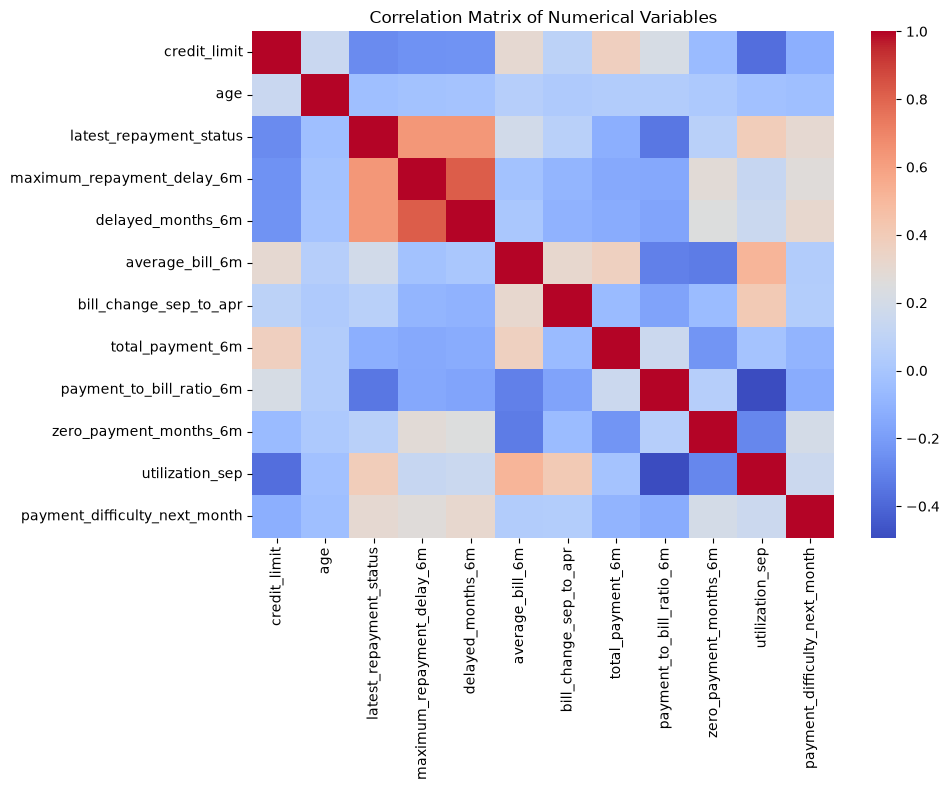

In [31]:
# Correlation matrix for numerical variables (adding the target to see relationships)
plt.figure(figsize=(10, 8))
numeric_cols = train_data.select_dtypes(include=['int64', 'float64']).columns
sns.heatmap(train_data[numeric_cols].corr(), annot=False, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()


In [32]:
from common import CATEGORICAL_COLUMNS, DATA_DICTIONARY, split_data

data_dictionary = DATA_DICTIONARY
categorical_columns = list(CATEGORICAL_COLUMNS)
split = split_data(train_data, test_data, data_dictionary)
predictor_columns = split.predictor_columns
target_column = split.target_column
X = split.X
y = split.y
X_train = split.X_train
X_validation = split.X_validation
y_train = split.y_train
y_validation = split.y_validation
X_test = split.X_test


In [33]:
from common import encode_features

encoded = encode_features(split, categorical_columns)
encoder = encoded.encoder
numerical_columns = encoded.numerical_columns
encoded_categorical_columns = encoded.encoded_categorical_columns
X_train_encoded = encoded.X_train
X_validation_encoded = encoded.X_validation
X_test_encoded = encoded.X_test


In [34]:
X_train_encoded.head()

,credit_limit,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,...,education_graduate_school,education_high_school,education_other,education_university,education_unknown,marital_status_married,marital_status_other_or_unknown,marital_status_single,repayment_assistance_plan_no,repayment_assistance_plan_yes
21143,60000,34,2,2,1,59000,-800,13500,0.04,0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
9555,80000,65,0,0,0,51600,77100,9600,0.03,0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
16143,160000,26,-1,0,0,11300,-8100,72400,1.07,0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
22939,20000,23,0,2,1,16400,-500,8000,0.08,1,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
11685,340000,62,0,0,0,495100,37800,116400,0.04,0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [35]:
from interpret.glassbox import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score
from sklearn.model_selection import StratifiedKFold

# Estimate performance across five stratified folds of the labeled training partition.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=411)
cv_scores = {
    "accuracy": [],
    "balanced_accuracy": [],
    "recall_class_0": [],
    "recall_class_1": [],
}

for train_indices, validation_indices in cv.split(X_train_encoded, y_train):
    fold_model = LogisticRegression(solver='liblinear', max_iter=1000, random_state=411)
    fold_model.fit(
        X_train_encoded.iloc[train_indices],
        y_train.iloc[train_indices],
    )
    fold_predictions = fold_model.predict(
        X_train_encoded.iloc[validation_indices]
    )
    fold_targets = y_train.iloc[validation_indices]
    cv_scores["accuracy"].append(accuracy_score(fold_targets, fold_predictions))
    cv_scores["balanced_accuracy"].append(balanced_accuracy_score(fold_targets, fold_predictions))
    cv_scores["recall_class_0"].append(recall_score(fold_targets, fold_predictions, pos_label=0))
    cv_scores["recall_class_1"].append(recall_score(fold_targets, fold_predictions, pos_label=1))

for metric_name, scores in cv_scores.items():
    print(f"Five-fold {metric_name}: {sum(scores) / len(scores):.3f} +/- {pd.Series(scores).std(ddof=0):.3f}")


Five-fold accuracy: 0.788 +/- 0.000
Five-fold balanced_accuracy: 0.501 +/- 0.001
Five-fold recall_class_0: 1.000 +/- 0.000
Five-fold recall_class_1: 0.002 +/- 0.002


In [36]:
from interpret import show
from interpret.data import ClassHistogram

hist = ClassHistogram().explain_data(X_train, y_train, name='Train Data')
show(hist)


<!-- http://127.0.0.1:7001/2598229422992/ -->

In [37]:
from interpret.glassbox import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report

logit = LogisticRegression(solver='liblinear', max_iter=1000, random_state=411)
logit.fit(X_train_encoded, y_train)

validation_predictions = logit.predict(X_validation_encoded)
print(f"Validation accuracy: {accuracy_score(y_validation, validation_predictions):.3f}")
print(f"Validation balanced accuracy: {balanced_accuracy_score(y_validation, validation_predictions):.3f}")
print(classification_report(y_validation, validation_predictions))


Validation accuracy: 0.788
Validation balanced accuracy: 0.501
              precision    recall  f1-score   support

           0       0.79      1.00      0.88      5909
           1       1.00      0.00      0.01      1591

    accuracy                           0.79      7500
   macro avg       0.89      0.50      0.44      7500
weighted avg       0.83      0.79      0.70      7500



In [38]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'class_weight': [None, 'balanced'],
}

search_model = SkLogisticRegression(
    solver='liblinear',
    max_iter=1000,
    random_state=411,
)

grid_search = GridSearchCV(
    estimator=search_model,
    param_grid=param_grid,
    scoring='balanced_accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=411),
    n_jobs=-1,
)

grid_search.fit(X_train_encoded, y_train)
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV balanced accuracy: {grid_search.best_score_:.3f}")


Best parameters: {'C': 100, 'class_weight': 'balanced'}
Best CV balanced accuracy: 0.671


In [39]:
# Re-train the logistic model with the best hyperparameters found
best_C = grid_search.best_params_['C']
best_class_weight = grid_search.best_params_['class_weight']

logit = LogisticRegression(
    C=best_C,
    class_weight=best_class_weight,
    solver='liblinear',
    max_iter=1000,
    random_state=411,
)
logit.fit(X_train_encoded, y_train)

validation_predictions = logit.predict(X_validation_encoded)
print(f"Validation accuracy with optimal hyperparameters: {accuracy_score(y_validation, validation_predictions):.3f}")
print(f"Validation balanced accuracy: {balanced_accuracy_score(y_validation, validation_predictions):.3f}")


Validation accuracy with optimal hyperparameters: 0.713
Validation balanced accuracy: 0.680


<!-- http://127.0.0.1:7001/2598230341136/ -->

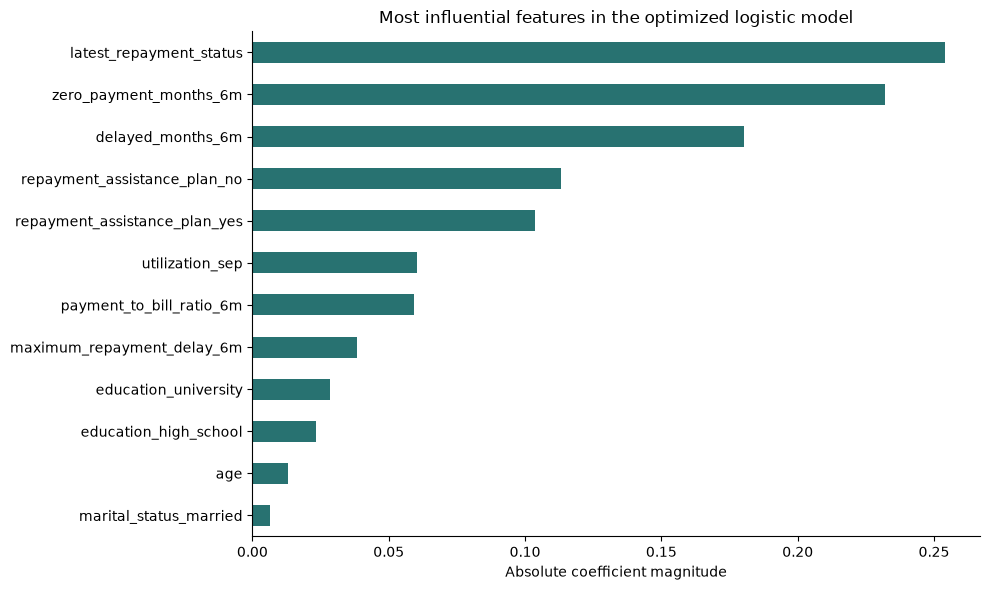

The fitted logistic model includes 23 coefficients and uses an intercept of -0.009.


In [40]:
from interpret import show

# Interpret the optimized model rather than the untuned baseline.
logit_global = logit.explain_global(name='Optimized Logistic Regression')
show(logit_global)

# InterpretML wraps the underlying scikit-learn model in sk_model_.
coefficients = logit.sk_model_.coef_[0]
coefficient_magnitudes = pd.Series(
    np.abs(coefficients),
    index=X_train_encoded.columns,
    name='absolute_coefficient',
)

top_global_importances = coefficient_magnitudes.nlargest(12).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
top_global_importances.plot.barh(ax=ax, color='#287271')
ax.set_title('Most influential features in the optimized logistic model')
ax.set_xlabel('Absolute coefficient magnitude')
ax.set_ylabel('')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig('../report/figures/logit_global_importance.png', dpi=240, bbox_inches='tight')
plt.show()

print(
    f"The fitted logistic model includes {len(X_train_encoded.columns)} coefficients and "
    f"uses an intercept of {logit.sk_model_.intercept_[0]:.3f}."
)


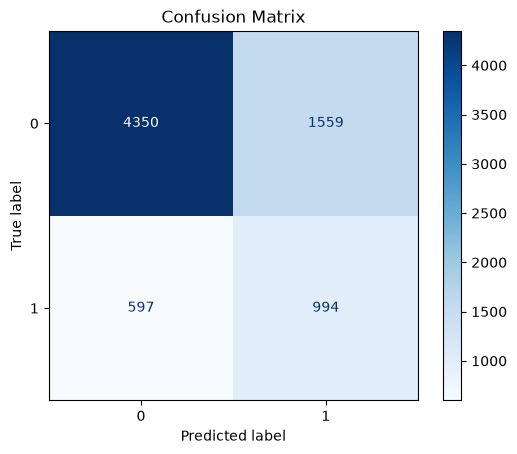

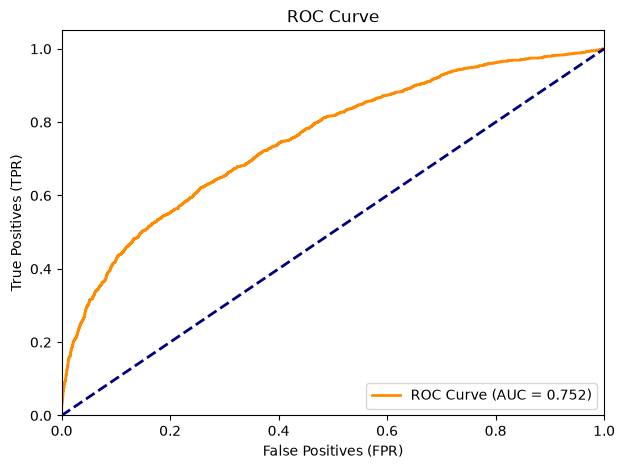

In [41]:
# Evaluation: Confusion matrix and ROC / AUC curve
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

# Confusion Matrix
cm = confusion_matrix(y_validation, validation_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logit.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.grid(False)
plt.show()

# ROC curve and AUC
y_proba = logit.predict_proba(X_validation_encoded)[:, 1]
fpr, tpr, _ = roc_curve(y_validation, y_proba)
auc_score = roc_auc_score(y_validation, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positives (FPR)')
plt.ylabel('True Positives (TPR)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


In [42]:
# Use fixed validation examples from both true classes, including errors when available.
validation_targets = y_validation.to_numpy()
validation_predictions_array = validation_predictions

class_zero_correct = np.flatnonzero(
    (validation_targets == 0) & (validation_predictions_array == 0)
)
class_one_correct = np.flatnonzero(
    (validation_targets == 1) & (validation_predictions_array == 1)
)
class_one_missed = np.flatnonzero(
    (validation_targets == 1) & (validation_predictions_array == 0)
)

local_positions = [
    int(class_zero_correct[0]) if len(class_zero_correct) else int(np.flatnonzero(validation_targets == 0)[0]),
]
local_labels = ['Class 0: correctly predicted' if len(class_zero_correct) else 'Class 0: model error']

if len(class_one_correct):
    local_positions.append(int(class_one_correct[0]))
    local_labels.append('Class 1: correctly detected')
if len(class_one_missed):
    local_positions.append(int(class_one_missed[0]))
    local_labels.append('Class 1: missed by the model')
if not len(class_one_correct) and not len(class_one_missed):
    local_positions.append(int(np.flatnonzero(validation_targets == 1)[0]))
    local_labels.append('Class 1: model error')

local_X = X_validation_encoded.iloc[local_positions]
local_y = y_validation.iloc[local_positions]
logit_local = logit.explain_local(local_X, local_y, name='Representative validation cases')

local_case_summary = pd.DataFrame(
    {
        'case': local_labels,
        'validation_row': X_validation.index[local_positions],
        'actual_class': local_y.to_numpy(),
        'predicted_class': validation_predictions_array[local_positions],
        'predicted_probability': logit.predict_proba(local_X)[:, 1],
    }
)

show(logit_local)
with pd.option_context('display.max_colwidth', None):
    display(local_case_summary)


<!-- http://127.0.0.1:7001/2598228559504/ -->

,case,validation_row,actual_class,predicted_class,predicted_probability
0,Class 0: correctly predicted,22764,0,0,0.130298
1,Class 1: correctly detected,4951,1,1,0.655938
2,Class 1: missed by the model,19211,1,0,0.376553


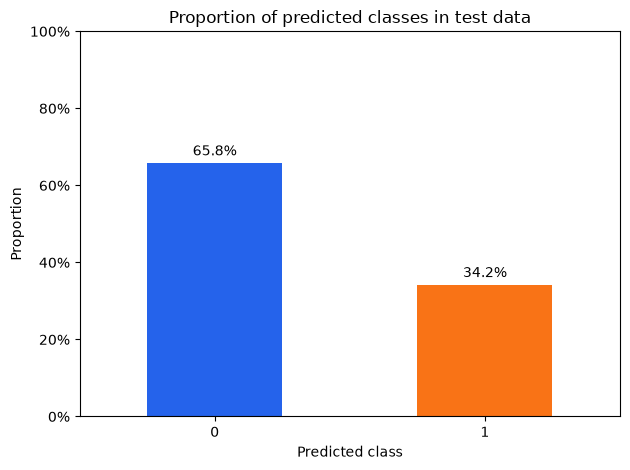

,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan,predicted_class
0,CR26-128173,50000,male,graduate_school,single,25,0,0,0,27700,31600,21700,0.13,0,0.80,no,0
1,CR26-102911,280000,female,university,married,41,1,1,1,100,300,600,0.63,4,0.00,no,1
2,CR26-104960,420000,male,university,married,38,0,0,0,262500,108200,56200,0.04,0,0.70,no,1
3,CR26-123913,270000,male,university,single,44,0,0,0,247400,48900,56400,0.04,0,1.02,no,1
4,CR26-111750,120000,female,graduate_school,single,29,-1,0,0,1700,-2100,12000,1.20,0,0.00,yes,0


In [43]:
# Classify the unlabeled test data and create a prediction file

import matplotlib.pyplot as plt
from common import create_submission, save_predictions

model_name = 'logistic_regression'
test_predictions = logit.predict(X_test_encoded)
submission = create_submission(test_data, test_predictions)
output_path = save_predictions(submission, model_name)

class_proportions = (
    submission['predicted_class']
    .value_counts(normalize=True)
    .sort_index()
)

ax = class_proportions.plot(
    kind='bar',
    color=['#2563eb', '#f97316'],
    title='Proportion of predicted classes in test data',
    ylabel='Proportion',
    xlabel='Predicted class',
    ylim=(0, 1),
)
ax.set_xticklabels(class_proportions.index, rotation=0)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'{value:.0%}')
)

for index, proportion in enumerate(class_proportions):
    ax.text(index, proportion + 0.02, f'{proportion:.1%}', ha='center')

plt.tight_layout()
plt.show()

submission.head()
